# Regime A/B 결함 탐지 방식 비교

운전 조건 A와 B의 정상 분포가 다르므로 기존 통합 탐지 모델이 두 레짐에서 공정하게 작동하는지 확인합니다.

비교 대상은 다음 세 가지입니다.

1. 통합 모델 + 공통 경보 규칙
2. 통합 모델 + 레짐별 경보 규칙
3. Regime A/B 개별 모델 + 레짐별 경보 규칙

모델과 경보 규칙 선택은 train과 validation에서만 수행하고 test는 마지막 비교에만 사용합니다. `fault_type`은 평가를 세분화하기 위한 정답이며 입력 특징에는 포함되지 않습니다.


## 0. 데이터와 이벤트 구성

현재 event split은 모든 결함 유형을 validation과 test에 포함하도록 설계됐지만, 레짐별 이벤트 수는 균등하지 않습니다. 특히 Test Regime A는 2개 이벤트뿐이므로 결과를 확정적인 결론으로 해석하면 안 됩니다.


                             events  fault_types
split      operating_regime                     
train      A                      8            4
           B                     11            4
validation A                      5            4
           B                      3            3
test       A                      2            2
           B                      6            4


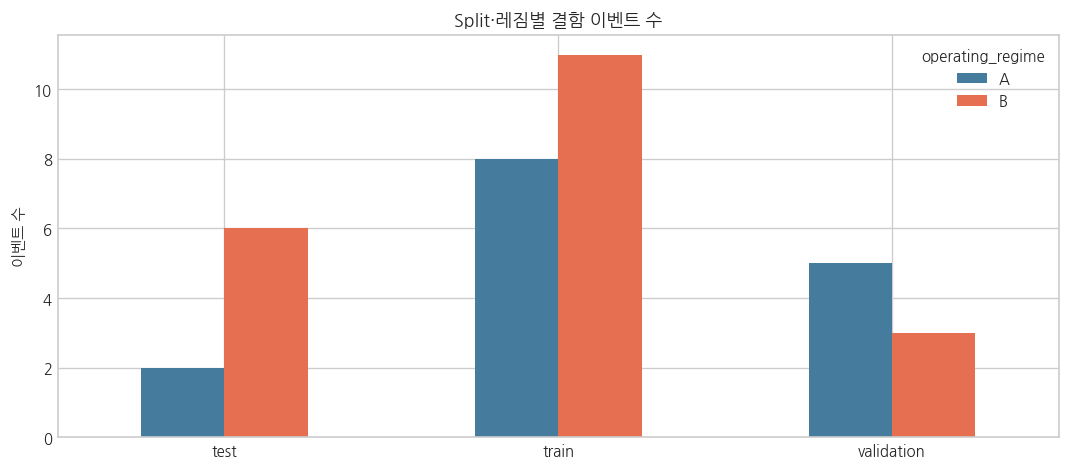

In [1]:
from pathlib import Path
import json,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import average_precision_score,roc_auc_score
import joblib

warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',180);pd.set_option('display.max_columns',30);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

DATA=Path('data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('data/modeling/feature_schema.json');MODEL=Path('models/binary_fault_detector_extratrees.joblib')
if not DATA.exists(): DATA=Path('../data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('../data/modeling/feature_schema.json');MODEL=Path('../models/binary_fault_detector_extratrees.joblib')
df=pd.read_csv(DATA);schema=json.loads(SCHEMA.read_text());feature_cols=schema['feature_columns'];global_model=joblib.load(MODEL)
assert 'fault_type' not in feature_cols and 'is_fault' not in feature_cols

event_table=(df[df['sample_kind'].eq('post_fault')].drop_duplicates('sample_event_id').groupby(['split','operating_regime']).agg(events=('sample_event_id','count'),fault_types=('fault_type','nunique')).reindex(pd.MultiIndex.from_product([['train','validation','test'],['A','B']],names=['split','operating_regime'])))
print(event_table.to_string())
fig,ax=plt.subplots(figsize=(9,4));event_table['events'].unstack().plot(kind='bar',ax=ax,color=['#457b9d','#e76f51']);ax.set_title('Split·레짐별 결함 이벤트 수');ax.set_xlabel('');ax.set_ylabel('이벤트 수');ax.tick_params(axis='x',rotation=0);plt.tight_layout();plt.show()


## 1. 평가 함수와 경보 규칙

확률 임계값을 일정 시간 연속으로 넘을 때 경보를 발생시킵니다. Validation에서 모든 이벤트를 탐지하고 사전 정상 구간 오탐이 24시간당 0.5건 이하인 후보 중 중앙 탐지 지연이 가장 짧은 규칙을 선택합니다.


In [2]:
def alert_indices(probability,threshold,persistence):
    signal=np.asarray(probability)>=threshold
    if len(signal)<persistence:return np.array([],dtype=int)
    sustained=np.convolve(signal,np.ones(persistence,dtype=int),mode='valid')==persistence
    return np.flatnonzero(sustained & np.r_[True,~sustained[:-1]])+persistence-1

def evaluate(frame,threshold,persistence):
    rows=[];false_alerts=0;normal_hours=0
    for event_id,g in frame.groupby('sample_event_id'):
        g=g.sort_values('relative_min');normal=g[g['sample_kind'].eq('pre_normal')];fault=g[g['sample_kind'].eq('post_fault')]
        normal_hours+=len(normal)/60;false_alerts+=len(alert_indices(normal['probability'],threshold,persistence));idx=alert_indices(fault['probability'],threshold,persistence)
        rows.append({'event_id':event_id,'regime':fault['operating_regime'].iloc[0],'fault_type':int(fault['fault_type'].iloc[0]),'detected':len(idx)>0,'delay_min':float(fault.iloc[idx[0]]['relative_min']) if len(idx) else np.nan})
    events=pd.DataFrame(rows)
    return {'event_count':len(events),'detected':int(events['detected'].sum()),'detection_rate':events['detected'].mean(),'median_delay_min':events['delay_min'].median(),'false_alerts':false_alerts,'false_alerts_per_24h':false_alerts/normal_hours*24 if normal_hours else np.nan},events

def tune(frame):
    rows=[]
    for persistence in [3,5,10]:
        for threshold in np.arange(.05,.61,.05):
            m,_=evaluate(frame,float(round(threshold,2)),persistence);m.update({'threshold':float(round(threshold,2)),'persistence':persistence});rows.append(m)
    grid=pd.DataFrame(rows);eligible=grid[(grid['detection_rate'].eq(1))&(grid['false_alerts_per_24h'].le(.5))]
    return eligible.sort_values(['median_delay_min','false_alerts_per_24h','persistence']).iloc[0],grid


## 2. 통합 모델의 공통 규칙을 레짐별로 평가

기존 모델은 `regime_B`, 설정값, 설정값 편차를 특징으로 사용하므로 운전 조건을 인식할 수 있는 통합 모델입니다. 기존 공통 규칙인 확률 0.25, 3분 연속을 레짐별로 나눠 평가합니다.


In [3]:
def prediction_frame(model,split,regime):
    x=df[df['split'].eq(split)&df['operating_regime'].eq(regime)][['sample_event_id','relative_min','sample_kind','fault_type','is_fault','operating_regime']].copy();x['probability']=model.predict_proba(df.loc[x.index,feature_cols])[:,1];return x

common_rows=[];common_events=[]
for regime in ['A','B']:
    frame=prediction_frame(global_model,'test',regime);metrics,events=evaluate(frame,.25,3);metrics.update({'approach':'통합 모델+공통 규칙','regime':regime,'threshold':.25,'persistence':3,'PR_AUC':average_precision_score(frame['is_fault'],frame['probability']),'ROC_AUC':roc_auc_score(frame['is_fault'],frame['probability'])});common_rows.append(metrics);events['approach']='통합 모델+공통 규칙';common_events.append(events)
print(pd.DataFrame(common_rows).set_index('regime').to_string())


        event_count  detected  detection_rate  median_delay_min  false_alerts  false_alerts_per_24h     approach  threshold  persistence  PR_AUC  ROC_AUC
regime                                                                                                                                                   
A                 2         2           1.000           106.000             0                 0.000  통합 모델+공통 규칙      0.250            3   0.836    0.877
B                 6         6           1.000            68.500             0                 0.000  통합 모델+공통 규칙      0.250            3   0.871    0.898


## 3. 통합 모델에 레짐별 경보 규칙 적용

모델은 그대로 두고 Validation A/B에서 임계값과 연속시간만 따로 선택합니다. 모델을 둘로 나누는 것보다 데이터 효율이 높습니다.


In [4]:
regime_rule_rows=[];regime_rule_events=[];selected_rules={}
for regime in ['A','B']:
    validation=prediction_frame(global_model,'validation',regime);selected,_=tune(validation);selected_rules[regime]={'threshold':float(selected['threshold']),'persistence':int(selected['persistence'])}
    test=prediction_frame(global_model,'test',regime);metrics,events=evaluate(test,selected_rules[regime]['threshold'],selected_rules[regime]['persistence']);metrics.update({'approach':'통합 모델+레짐별 규칙','regime':regime,**selected_rules[regime],'PR_AUC':average_precision_score(test['is_fault'],test['probability']),'ROC_AUC':roc_auc_score(test['is_fault'],test['probability'])});regime_rule_rows.append(metrics);events['approach']='통합 모델+레짐별 규칙';regime_rule_events.append(events)
print('선택 규칙:',selected_rules);print(pd.DataFrame(regime_rule_rows).set_index('regime').to_string())


선택 규칙: {'A': {'threshold': 0.2, 'persistence': 3}, 'B': {'threshold': 0.25, 'persistence': 3}}
        event_count  detected  detection_rate  median_delay_min  false_alerts  false_alerts_per_24h      approach  threshold  persistence  PR_AUC  ROC_AUC
regime                                                                                                                                                    
A                 2         2           1.000           103.500             1                 0.500  통합 모델+레짐별 규칙      0.200            3   0.836    0.877
B                 6         6           1.000            68.500             0                 0.000  통합 모델+레짐별 규칙      0.250            3   0.871    0.898


## 4. Regime A/B 개별 모델

각 레짐의 train 행만 사용해 별도 Extra Trees 모델을 학습하고 해당 레짐 validation에서 규칙을 조정합니다. 데이터가 절반으로 줄어 과적합과 이벤트 다양성 부족 위험이 있습니다.


In [5]:
separate_models={};separate_rules={};separate_rows=[];separate_events=[]
for regime in ['A','B']:
    train_mask=df['split'].eq('train')&df['operating_regime'].eq(regime)
    model=ExtraTreesClassifier(n_estimators=300,min_samples_leaf=3,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=42).fit(df.loc[train_mask,feature_cols],df.loc[train_mask,'is_fault']);separate_models[regime]=model
    validation=prediction_frame(model,'validation',regime);selected,_=tune(validation);separate_rules[regime]={'threshold':float(selected['threshold']),'persistence':int(selected['persistence'])}
    test=prediction_frame(model,'test',regime);metrics,events=evaluate(test,separate_rules[regime]['threshold'],separate_rules[regime]['persistence']);metrics.update({'approach':'레짐별 개별 모델','regime':regime,**separate_rules[regime],'PR_AUC':average_precision_score(test['is_fault'],test['probability']),'ROC_AUC':roc_auc_score(test['is_fault'],test['probability'])});separate_rows.append(metrics);events['approach']='레짐별 개별 모델';separate_events.append(events)
print('선택 규칙:',separate_rules);print(pd.DataFrame(separate_rows).set_index('regime').to_string())


선택 규칙: {'A': {'threshold': 0.2, 'persistence': 5}, 'B': {'threshold': 0.15, 'persistence': 10}}
        event_count  detected  detection_rate  median_delay_min  false_alerts  false_alerts_per_24h   approach  threshold  persistence  PR_AUC  ROC_AUC
regime                                                                                                                                                 
A                 2         2           1.000           104.500             0                 0.000  레짐별 개별 모델      0.200            5   0.835    0.879
B                 6         6           1.000            58.500             7                 1.167  레짐별 개별 모델      0.150           10   0.873    0.901


## 5. 세 방식 비교

탐지 지연뿐 아니라 정상 구간 오탐을 함께 봅니다. Test Regime A는 이벤트 2개뿐이므로 수 분 차이에 큰 의미를 부여하지 않습니다.


    approach regime  event_count  detected  median_delay_min  false_alerts_per_24h  PR_AUC  ROC_AUC  threshold  persistence
 통합 모델+공통 규칙      A            2         2           106.000                 0.000   0.836    0.877      0.250            3
 통합 모델+공통 규칙      B            6         6            68.500                 0.000   0.871    0.898      0.250            3
통합 모델+레짐별 규칙      A            2         2           103.500                 0.500   0.836    0.877      0.200            3
통합 모델+레짐별 규칙      B            6         6            68.500                 0.000   0.871    0.898      0.250            3
   레짐별 개별 모델      A            2         2           104.500                 0.000   0.835    0.879      0.200            5
   레짐별 개별 모델      B            6         6            58.500                 1.167   0.873    0.901      0.150           10

이벤트별 결과
 event_id regime  fault_type  detected  delay_min     approach
       32      A           4      True     24.000  통합 모델+공통 

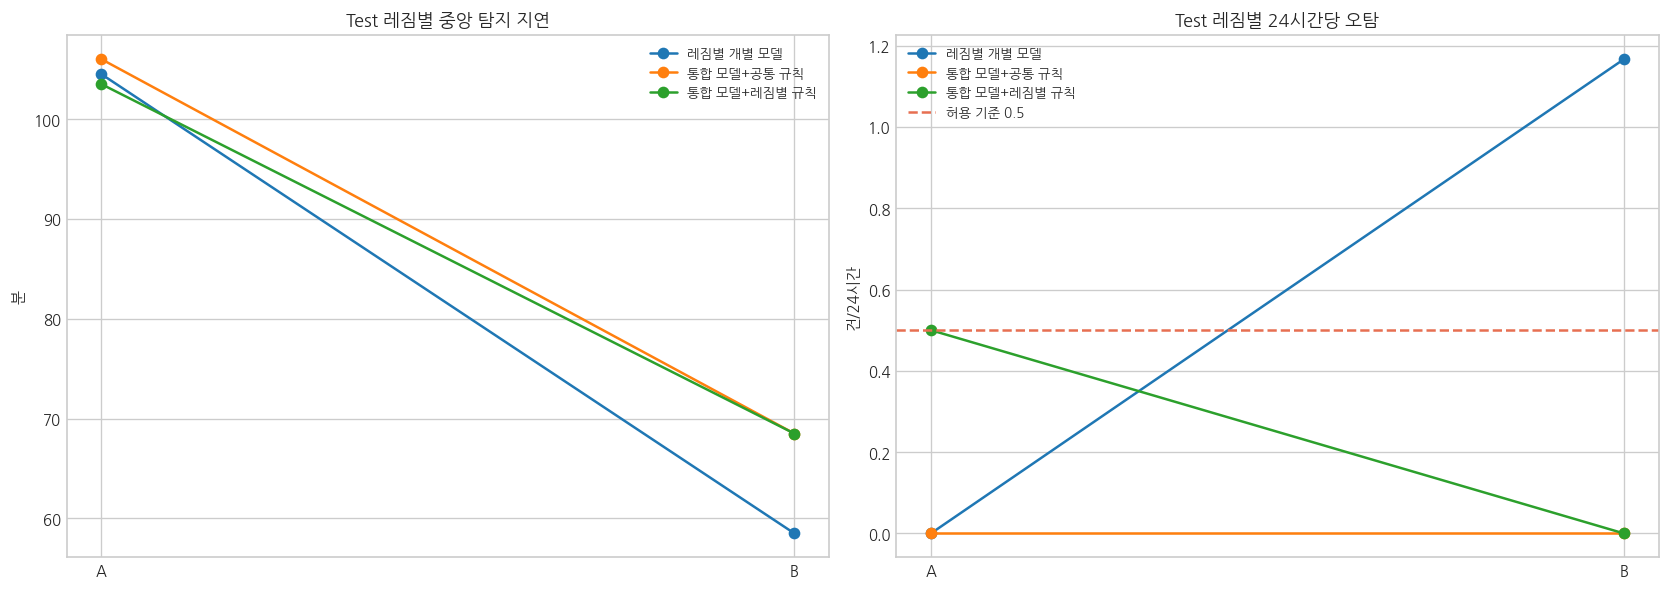

In [6]:
comparison=pd.concat([pd.DataFrame(common_rows),pd.DataFrame(regime_rule_rows),pd.DataFrame(separate_rows)],ignore_index=True)
print(comparison[['approach','regime','event_count','detected','median_delay_min','false_alerts_per_24h','PR_AUC','ROC_AUC','threshold','persistence']].to_string(index=False))

fig,axes=plt.subplots(1,2,figsize=(14,5))
for approach,g in comparison.groupby('approach'):
    axes[0].plot(g['regime'],g['median_delay_min'],marker='o',label=approach);axes[1].plot(g['regime'],g['false_alerts_per_24h'],marker='o',label=approach)
axes[0].set_title('Test 레짐별 중앙 탐지 지연');axes[0].set_ylabel('분');axes[1].set_title('Test 레짐별 24시간당 오탐');axes[1].set_ylabel('건/24시간');axes[1].axhline(.5,color='#e76f51',linestyle='--',label='허용 기준 0.5')
for ax in axes:ax.legend(fontsize=8)
plt.tight_layout();plt.show()

all_events=pd.concat(common_events+regime_rule_events+separate_events,ignore_index=True)
print('\n이벤트별 결과');print(all_events.to_string(index=False))


## 6. 감사 결과 저장

이 비교에서는 기존 통합 모델을 유지합니다. 레짐별 개별 모델은 Regime B의 지연을 일부 줄였지만 Test 정상 구간 오탐이 증가했고 Regime A 표본도 부족합니다.


In [7]:
audit={'event_counts':event_table.reset_index().to_dict(orient='records'),'common_rule':{'threshold':.25,'persistence':3},'global_model_regime_rules':selected_rules,'separate_model_rules':separate_rules,'test_comparison':comparison.to_dict(orient='records'),'recommendation':'Keep the global condition-aware model with the common rule until more regime-specific events are available.'}
path=Path('models/regime_detection_audit.json');path.write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8');print(path)


models/regime_detection_audit.json


## 7. 결론

- 기존 모델은 레짐을 무시한 모델이 아니라 `regime_B`와 설정값을 포함한 조건 인식 통합 모델입니다.
- 공통 규칙에서도 Test A/B 이벤트를 모두 탐지했고 이벤트 주변 정상 구간 오탐은 없었습니다.
- 통합 모델의 레짐별 규칙은 Regime A에서 몇 분 빨라졌지만 오탐이 증가했습니다.
- A/B 개별 모델은 Regime B 탐지를 일부 앞당겼지만 24시간당 오탐이 1건 이상 발생했습니다.
- Test Regime A가 2개뿐이어서 A 전용 모델을 신뢰하기 어렵습니다.

따라서 현재 데이터에서는 **통합 조건 인식 모델 + 공통 규칙**을 유지하는 편이 안전합니다. 데이터가 늘어나면 레짐별 모델을 다시 비교해야 합니다. 다음 단계의 F1~F4 유형 분류에서도 반드시 레짐을 특징에 포함하고 레짐별 성능을 따로 보고해야 합니다.
